In [ ]:
# Chapter 12: Cross-Validation and Model Evaluation

## 1. Ringkasan Bab
Evaluasi kinerja model yang objektif dan bebas bias merupakan syarat mutlak sebelum suatu sistem machine learning diimplementasikan ke lingkungan produksi. Menguji model hanya pada data pelatihan atau pemisahan data latih/uji tunggal (*train/test split*) sering kali memberikan estimasi performa yang keliru akibat variansi pengambilan sampel.

Bab ini membahas teknik validasi dan metrik asesmen komprehensif:
- **Strategi Validasi Silang (Cross-Validation / CV)**: K-Fold CV dasar, Stratified K-Fold untuk data dengan distribusi kelas tidak seimbang, serta evaluasi cepat menggunakan `cross_val_score` dan `cross_validate`.
- **Pencarian Hyperparameter Lanjutan**:
  - `GridSearchCV`: Pencarian menyeluruh pada ruang kombinasi diskret.
  - `RandomizedSearchCV`: Pengambilan sampel acak berbasis distribusi statistik untuk ruang parameter yang luas.
- **Nested Cross-Validation**: Validasi silang bersarang untuk mengisolasi proses optimasi parameter dari estimasi kesalahan generalisasi sebenarnya.
- **Metrik Asesmen Diagnostik**: Kurva validasi (*Validation Curves*) untuk menganalisis trade-off bias-variansi pada parameter tertentu, kurva pembelajaran (*Learning Curves*), serta kurva presisi-recall (*Precision-Recall Curves*).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    cross_val_score, cross_validate,
    GridSearchCV, RandomizedSearchCV,
    validation_curve, learning_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, f1_score, precision_recall_curve, average_precision_score
from scipy.stats import randint, uniform
import warnings

np.random.seed(2024)
warnings.filterwarnings('ignore')

print("Pustaka dan dependensi Chapter 12 berhasil dimuat.")

Pustaka dan dependensi Chapter 12 berhasil dimuat.


## 2. Strategi Validasi Silang: K-Fold vs. Stratified K-Fold

Validasi silang membagi data menjadi $k$ kelompok (*folds*) berukuran sama. Setiap iterasi menggunakan $k-1$ fold untuk pelatihan dan 1 fold tersisa untuk validasi, diulang sebanyak $k$ kali hingga seluruh sampel pernah menjadi data evaluasi.

1. **Standard K-Fold (`KFold`)**: Membagi data secara acak tanpa mempertimbangkan proporsi target.
2. **Stratified K-Fold (`StratifiedKFold`)**: Memastikan setiap fold memiliki persentase distribusi label kelas yang identik dengan populasi data utuh. Sangat esensial untuk klasifikasi dengan ketidakseimbangan kelas (*imbalanced data*).

In [3]:
# Memuat dataset Breast Cancer
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target
feature_names = cancer.feature_names
target_names = cancer.target_names

# Inisialisasi Model Dasar
rf_base = RandomForestClassifier(n_estimators=50, random_state=2024)

# 1. Evaluasi dengan Standard K-Fold (k=5)
kf = KFold(n_splits=5, shuffle=True, random_state=2024)
scores_kf = cross_val_score(rf_base, X, y, cv=kf, scoring='accuracy')

# 2. Evaluasi dengan Stratified K-Fold (k=5)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
scores_skf = cross_val_score(rf_base, X, y, cv=skf, scoring='accuracy')

print("=== Komparasi Kinerja Validasi Silang (k=5) ===")
print(f"Standard K-Fold   : Rata-rata = {scores_kf.mean():.4f} (+/- {scores_kf.std():.4f})")
print(f"Stratified K-Fold : Rata-rata = {scores_skf.mean():.4f} (+/- {scores_skf.std():.4f})")

# 3. Evaluasi Multi-Metrik menggunakan cross_validate
scoring_metrics = {'acc': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc'}
cv_results = cross_validate(rf_base, X, y, cv=skf, scoring=scoring_metrics)

print("\n=== Ringkasan Multi-Metrik (Stratified CV) ===")
print(f"Rata-rata Akurasi : {cv_results['test_acc'].mean():.4f}")
print(f"Rata-rata F1-Score: {cv_results['test_f1'].mean():.4f}")
print(f"Rata-rata ROC-AUC : {cv_results['test_roc_auc'].mean():.4f}")

=== Komparasi Kinerja Validasi Silang (k=5) ===
Standard K-Fold   : Rata-rata = 0.9473 (+/- 0.0166)
Stratified K-Fold : Rata-rata = 0.9578 (+/- 0.0197)

=== Ringkasan Multi-Metrik (Stratified CV) ===
Rata-rata Akurasi : 0.9578
Rata-rata F1-Score: 0.9664
Rata-rata ROC-AUC : 0.9897


## 3. Optimasi Hyperparameter: GridSearchCV vs. RandomizedSearchCV

Pencarian konfigurasi parameter optimal dapat dilakukan melalui dua metode:
- **`GridSearchCV`**: Menguji setiap kombinasi parameter secara menyeluruh. Tepat untuk ruang diskret kecil, namun sangat lambat jika kombinasi parameter berlipat ganda.
- **`RandomizedSearchCV`**: Mengambil sampel kombinasi secara acak sebanyak `n_iter` dari ruang parameter kontinu atau diskret. Menghasilkan parameter yang kompetitif dalam waktu komputasi yang jauh lebih efisien.

In [4]:
# Pembagian Data Latih dan Uji Awal (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024, stratify=y
)

# 1. Implementasi GridSearchCV
grid_params = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 8],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=2024),
    grid_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

# 2. Implementasi RandomizedSearchCV
dist_params = {
    'n_estimators': randint(30, 150),
    'max_depth': randint(2, 10),
    'min_samples_split': randint(2, 10)
}

random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=2024),
    dist_params,
    n_iter=12,
    cv=5,
    scoring='f1',
    random_state=2024,
    n_jobs=-1
)
random_search.fit(X_train, y_train)

print("=== Hasil Optimasi Hyperparameter ===")
print("GridSearchCV      -> Parameter Terbaik:", grid_search.best_params_)
print(f"                     Skor CV Terbaik  : {grid_search.best_score_:.4f}")
print("RandomizedSearchCV-> Parameter Terbaik:", random_search.best_params_)
print(f"                     Skor CV Terbaik  : {random_search.best_score_:.4f}")

=== Hasil Optimasi Hyperparameter ===
GridSearchCV      -> Parameter Terbaik: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 50}
                     Skor CV Terbaik  : 0.9775
RandomizedSearchCV-> Parameter Terbaik: {'max_depth': 4, 'min_samples_split': 8, 'n_estimators': 125}
                     Skor CV Terbaik  : 0.9723


## 4. Nested Cross-Validation (Validasi Silang Bersarang)

Saat mengoptimasi hyperparameter menggunakan validasi silang biasa, skor validasi terbaik cenderung mengalami bias optimistik karena model dipilih berdasarkan data validasi tersebut.

**Nested Cross-Validation** memisahkan fungsi ini ke dalam dua lapis putaran:
- **Inner Loop**: Bertanggung jawab mencari kombinasi hyperparameter terbaik.
- **Outer Loop**: Mengevaluasi kemampuan generalisasi model optimal pada lipatan data yang sepenuhnya independen.

In [5]:
# Konfigurasi Nested Cross-Validation
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=2024)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)

# Model yang membungkus pencarian inner-loop
clf_nested = GridSearchCV(
    estimator=RandomForestClassifier(random_state=2024),
    param_grid={'max_depth': [3, 5, 7], 'n_estimators': [50, 100]},
    cv=inner_cv,
    scoring='accuracy'
)

# Evaluasi generalisasi sebenarnya pada outer-loop
nested_scores = cross_val_score(clf_nested, X, y, cv=outer_cv, scoring='accuracy')

print("=== Hasil Evaluasi Nested Cross-Validation ===")
print("Skor Akurasi Tiap Outer Fold :", np.round(nested_scores, 4))
print(f"Rata-rata Akurasi Generalisasi: {nested_scores.mean():.4f} (+/- {nested_scores.std():.4f})")

=== Hasil Evaluasi Nested Cross-Validation ===
Skor Akurasi Tiap Outer Fold : [0.9474 0.9649 0.9825 0.9474 0.9292]
Rata-rata Akurasi Generalisasi: 0.9543 (+/- 0.0181)


## 5. Kurva Validasi (Validation Curve)

`validation_curve` menguji performa model terhadap variasi nilai satu hyperparameter tertentu untuk mendeteksi batas transisi antara *underfitting* dan *overfitting*.

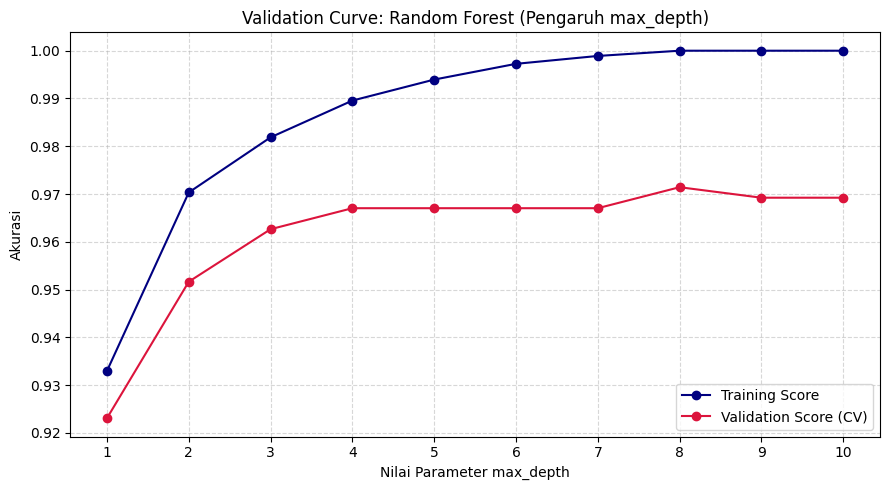

In [6]:
# Plot Validation Curve terhadap Variasi max_depth
param_range = np.arange(1, 11)
train_scores, val_scores = validation_curve(
    RandomForestClassifier(n_estimators=50, random_state=2024),
    X_train, y_train,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(9, 5))
plt.plot(param_range, train_mean, 'o-', color='navy', label='Training Score')
plt.plot(param_range, val_mean, 'o-', color='crimson', label='Validation Score (CV)')
plt.title('Validation Curve: Random Forest (Pengaruh max_depth)', fontsize=12)
plt.xlabel('Nilai Parameter max_depth')
plt.ylabel('Akurasi')
plt.xticks(param_range)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Kurva Precision-Recall (PR Curve)

Pada dataset yang memiliki disparitas distribusi kelas yang tinggi, kurva ROC terkadang memberikan gambaran optimistik semu. **Kurva Precision-Recall** menyajikan representasi yang lebih jujur mengenai trade-off antara ketepatan (*precision*) dan sensitivitas cakupan (*recall*).

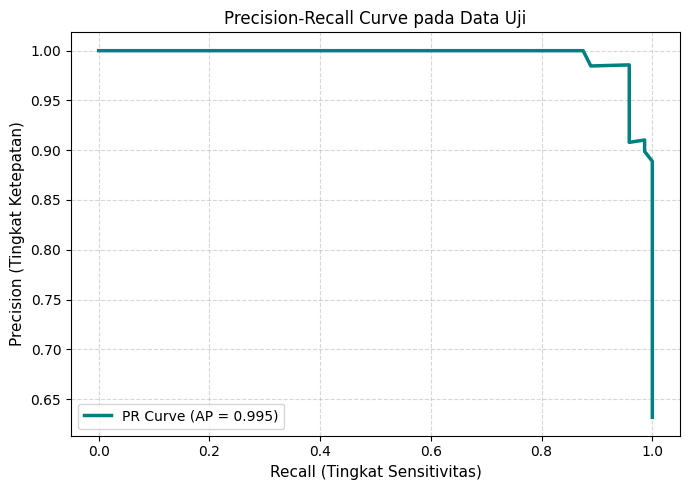

In [7]:
# Pelatihan Model Terbaik pada Data Latih dan Inferensi Probabilitas
best_model = grid_search.best_estimator_
y_probs = best_model.predict_proba(X_test)[:, 1]

precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_probs)
ap_score = average_precision_score(y_test, y_probs)

# Plot Kurva Precision-Recall
plt.figure(figsize=(7, 5))
plt.plot(recall_vals, precision_vals, color='teal', lw=2.5, label=f'PR Curve (AP = {ap_score:.3f})')
plt.xlabel('Recall (Tingkat Sensitivitas)', fontsize=11)
plt.ylabel('Precision (Tingkat Ketepatan)', fontsize=11)
plt.title('Precision-Recall Curve pada Data Uji', fontsize=12)
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Analisis dan Kesimpulan
1. **Keandalan Stratifikasi**: Penerapan `StratifiedKFold` menjaga konsistensi proporsi kelas target di setiap subset evaluasi, meminimalkan deviasi skor performa antar-fold dibanding K-Fold konvensional.
2. **Efisiensi Pencarian Acak**: `RandomizedSearchCV` mampu menemukan titik hyperparameter dengan skor performa yang sebanding terhadap `GridSearchCV`, dengan waktu pemrosesan yang jauh lebih ringkas.
3. **Objektivitas Nested CV**: Pengujian bersarang (*Nested Cross-Validation*) mencegah kebocoran informasi dari tahapan seleksi parameter ke evaluasi akhir, memberikan estimasi batas performa generalisasi yang paling realistis.
4. **Analisis Kurva Diagnostik**: Kurva validasi mengindikasikan bahwa peningkatan `max_depth` di luar ambang tertentu hanya memicu kenaikan skor data latih tanpa perbaikan pada skor validasi silang (indikasi awal terjadinya saturasi generalisasi).